# 04 — News EDA (exploratory analysis of the news data)

## Purpose
Describe the news data **before** using it for sentiment-versus-return, risk or machine learning work. This answers: how much news does each company get, when, from where, how many articles are market roundups, and how positive or negative is it?

## Inputs (`data/processed/`)
| File | Grain | Used for |
|---|---|---|
| `news_articles_sentiment.csv` | one row per article | text fields, sources, FinBERT sentiment |
| `news_tickers.csv` (v2) | one row per article-ticker pair | which company an article is about, `n_symbols_total`, `reaction_date` |
| `market_clean.csv` | one row per ticker and trading day | the list of trading days |

## Outputs
Charts and tables in this notebook, five written findings at the end, and `news_eda_summary.csv` (one row per ticker) in `data/processed/` for the report.

## Why there is no daily news table
Articles are not spread evenly over days. Section 4 measures, for each ticker, the share of trading days with **no** article. If that share is large, a daily average sentiment would be built on very few articles and would be noise, so we use article-level, monthly and trailing-window views instead.

## Terms
- **Reaction date:** the first trading day the market could react to an article (New York time; after 16:00, weekends and holidays roll to the next trading day).
- **Roundup:** an article tagged with many tickers (`n_symbols_total` above 3). Its sentiment is about the market or a list of stocks, not about one company.
- **FinBERT score:** `P(positive) - P(negative)`, from -1 (negative) to +1 (positive). It describes the article text, not a specific company.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

PROCESSED_DIR = Path("../../data/processed")
ARTICLES_PATH = PROCESSED_DIR / "news_articles_sentiment.csv"
PAIRS_PATH = PROCESSED_DIR / "news_tickers.csv"
MARKET_PATH = PROCESSED_DIR / "market_clean.csv"
SUMMARY_OUT = PROCESSED_DIR / "news_eda_summary.csv"

TICKERS = ["AAPL", "JPM", "MSFT", "NVDA", "JNJ", "XOM", "KO", "AMZN", "LLY", "TSLA"]
FOCUSED_MAX = 3          # an article with this many tickers or fewer is "focused"

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load the data

`content` is not loaded (it is not in the file by default). IDs are read as text.

In [2]:
for path in [ARTICLES_PATH, PAIRS_PATH, MARKET_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Could not find {path.resolve()}")

wanted = ["article_id", "published_at", "title", "summary", "source", "finbert_label", "finbert_score"]
articles = pd.read_csv(ARTICLES_PATH, usecols=lambda c: c in wanted, dtype={"article_id": str})
articles["published_at"] = pd.to_datetime(articles["published_at"], utc=True, errors="coerce")

pairs = pd.read_csv(PAIRS_PATH, dtype={"article_id": str, "ticker": str})
pairs["reaction_date"] = pd.to_datetime(pairs["reaction_date"], errors="coerce")
pairs["published_at"] = pd.to_datetime(pairs["published_at"], utc=True, errors="coerce")

trading_days = pd.DatetimeIndex(sorted(pd.to_datetime(pd.read_csv(MARKET_PATH, usecols=["date"])["date"]).unique()))

required_pair_cols = {"article_id", "ticker", "n_symbols_total", "n_project_tickers", "reaction_date"}
missing = required_pair_cols - set(pairs.columns)
if missing:
    raise ValueError(f"news_tickers.csv is missing {sorted(missing)}. Run 03_news_ticker_mapping_v2 first.")

# Article-ticker rows with the article-level sentiment attached
pairs = pairs.merge(
    articles[["article_id", "finbert_label", "finbert_score"]], on="article_id", how="left", validate="many_to_one"
)
pairs["is_focused"] = pairs["n_symbols_total"] <= FOCUSED_MAX
pairs["month"] = pairs["published_at"].dt.tz_localize(None).dt.to_period("M")

print(f"Articles:                 {len(articles):>8,}")
print(f"Article-ticker pairs:     {len(pairs):>8,}")
print(f"Trading days in prices:   {len(trading_days):>8,}  ({trading_days.min().date()} to {trading_days.max().date()})")
print(f"Articles per pair (mean): {len(pairs) / articles['article_id'].nunique():>8.2f}")

Articles:                   79,549
Article-ticker pairs:      102,767
Trading days in prices:      1,254  (2021-01-04 to 2025-12-30)
Articles per pair (mean):     1.29


## 2. Articles per company

One article tagged with two project tickers counts once for each ticker. The second column counts distinct articles.

,pairs,distinct_articles,share_of_pairs,avg_per_trading_day
ticker,,,,
TSLA,26896,26896,26.2%,21.45
AAPL,19354,19354,18.8%,15.43
AMZN,14906,14906,14.5%,11.89
NVDA,14754,14754,14.4%,11.77
MSFT,13346,13346,13.0%,10.64
JPM,3646,3646,3.5%,2.91
JNJ,3320,3320,3.2%,2.65
LLY,3142,3142,3.1%,2.51
XOM,2144,2144,2.1%,1.71


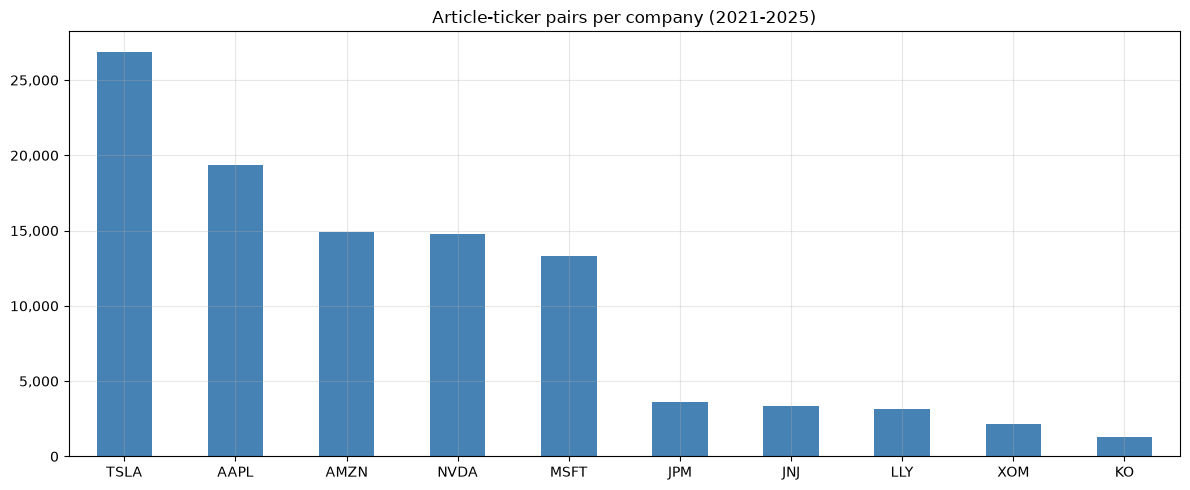

In [3]:
per_ticker = (
    pairs.groupby("ticker")
    .agg(pairs=("article_id", "size"), distinct_articles=("article_id", "nunique"))
    .reindex(TICKERS)
    .fillna(0).astype(int)
)
per_ticker["share_of_pairs"] = per_ticker["pairs"] / per_ticker["pairs"].sum()
per_ticker["avg_per_trading_day"] = per_ticker["pairs"] / len(trading_days)
display(per_ticker.sort_values("pairs", ascending=False).style.format({"share_of_pairs": "{:.1%}", "avg_per_trading_day": "{:.2f}"}))

ax = per_ticker["pairs"].sort_values(ascending=False).plot(kind="bar", color="steelblue", rot=0)
ax.set_title("Article-ticker pairs per company (2021-2025)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()
plt.close("all")

## 3. Articles over time

Monthly counts by calendar month of the UTC publication time. This is a coverage audit: a month with a very low count points to a collection gap, not to a quiet month.

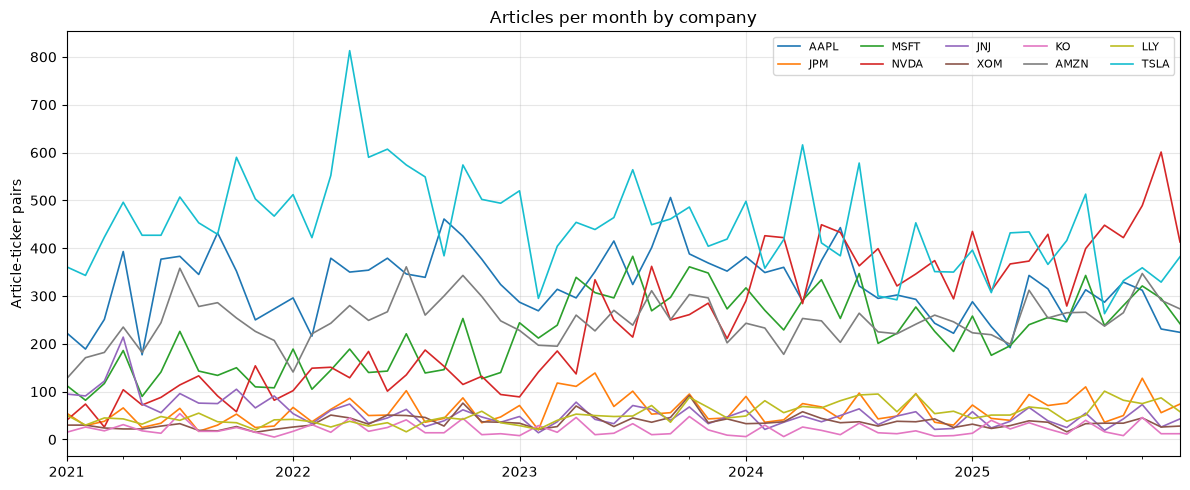

,min_month,median_month,max_month,months_below_5
ticker,,,,
AAPL,177,324,506,0
JPM,17,53,139,0
MSFT,82,227,383,0
NVDA,26,232,601,0
JNJ,14,49,214,0
XOM,15,34,92,0
KO,5,17,54,0
AMZN,127,248,361,0
LLY,16,49,101,0


Months with zero articles (all tickers): 0
Ticker-months with fewer than 5 articles: 0 of 600


In [4]:
monthly = pairs.dropna(subset=["month"]).pivot_table(index="month", columns="ticker", values="article_id", aggfunc="size", fill_value=0)
monthly = monthly.reindex(columns=TICKERS, fill_value=0)
monthly = monthly.reindex(pd.period_range("2021-01", "2025-12", freq="M"), fill_value=0)

monthly_plot = monthly.copy()
monthly_plot.index = pd.PeriodIndex(monthly_plot.index, freq="M").to_timestamp()
fig, ax = plt.subplots()
monthly_plot.plot(ax=ax, linewidth=1.2)
ax.set_title("Articles per month by company")
ax.set_xlabel("")
ax.set_ylabel("Article-ticker pairs")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()
plt.close("all")

stats = pd.DataFrame({
    "min_month": monthly.min(),
    "median_month": monthly.median(),
    "max_month": monthly.max(),
    "months_below_5": (monthly < 5).sum(),
}).astype(int)
display(stats)

total_monthly = monthly.sum(axis=1)
print("Months with zero articles (all tickers):", int((total_monthly == 0).sum()))
print("Ticker-months with fewer than 5 articles:", int((monthly < 5).sum().sum()), "of", monthly.size)

## 4. News frequency: how many trading days have no article?

For each ticker, every trading day is checked against the article counts by `reaction_date`. Reaction dates after the last price day are ignored.

,trading_days,days_with_article,days_without_article,share_days_without,mean_on_days_with,max_in_one_day
ticker,,,,,,
KO,1254,596,658,52.5%,2.1,18
XOM,1254,901,353,28.1%,2.4,24
LLY,1254,1011,243,19.4%,3.1,20
JNJ,1254,1029,225,17.9%,3.2,49
JPM,1254,1067,187,14.9%,3.4,34
NVDA,1254,1224,30,2.4%,12.0,102
MSFT,1254,1251,3,0.2%,10.7,71
AAPL,1254,1254,0,0.0%,15.4,161
AMZN,1254,1254,0,0.0%,11.9,62


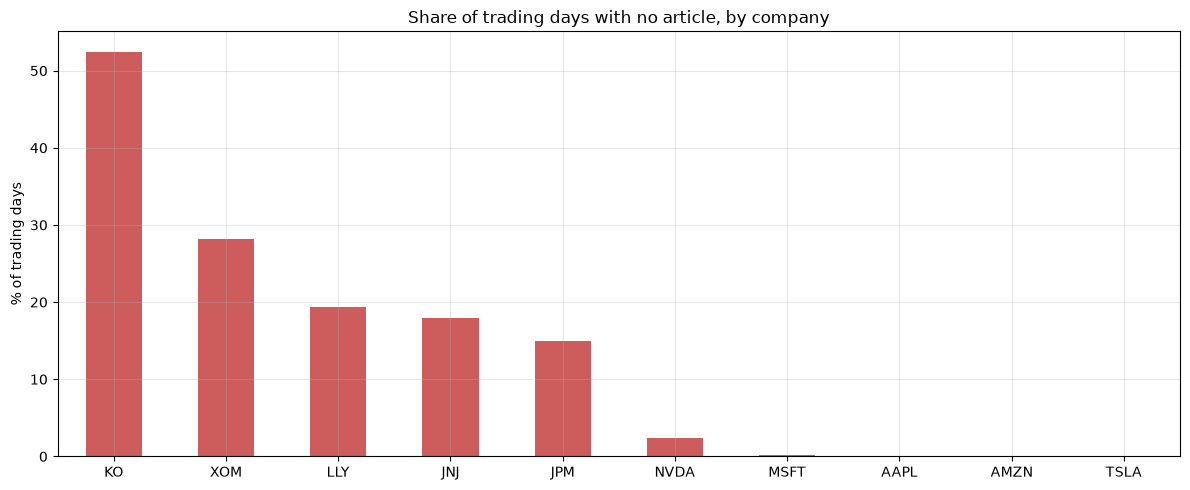

In [5]:
counts = (
    pairs.dropna(subset=["reaction_date"])
    .groupby(["ticker", "reaction_date"]).size()
    .unstack("ticker").reindex(trading_days).reindex(columns=TICKERS).fillna(0)
)
days_with = (counts > 0).sum()
freq = pd.DataFrame({
    "trading_days": len(trading_days),
    "days_with_article": days_with,
    "days_without_article": len(trading_days) - days_with,
    "share_days_without": 1 - days_with / len(trading_days),
    "mean_on_days_with": counts.where(counts > 0).mean(),
    "max_in_one_day": counts.max(),
})
display(freq.sort_values("share_days_without", ascending=False).style.format({
    "share_days_without": "{:.1%}", "mean_on_days_with": "{:.1f}", "max_in_one_day": "{:.0f}"}))

ax = (freq["share_days_without"].sort_values(ascending=False) * 100).plot(kind="bar", color="indianred", rot=0)
ax.set_title("Share of trading days with no article, by company")
ax.set_ylabel("% of trading days")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
plt.close("all")

## 5. Roundups: how many tickers does an article carry?

`n_symbols_total` is the number of tickers Alpaca tagged on the article (all companies, not only ours). Many tags usually mean a market roundup or a list article.

,articles,share
n_symbols_total,,
1,31497,39.6%
2-3,19877,25.0%
4-10,23121,29.1%
11-50,4568,5.7%
51+,486,0.6%


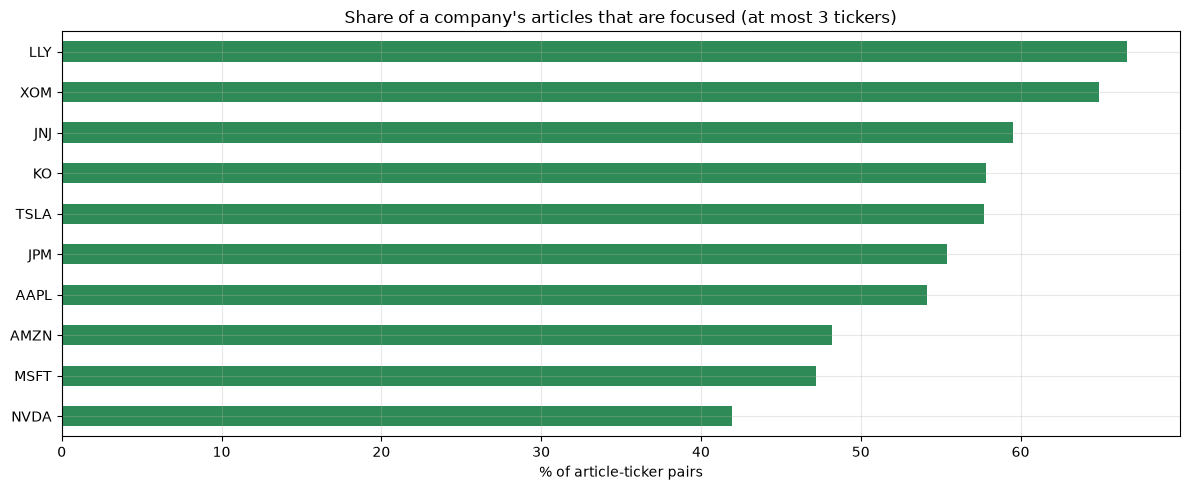

Pairs from roundup articles (more than 3 tickers): 47.6%


In [6]:
art_pairs = pairs.drop_duplicates("article_id")
bins = pd.cut(art_pairs["n_symbols_total"], [0, 1, 3, 10, 50, np.inf], labels=["1", "2-3", "4-10", "11-50", "51+"])
dist = bins.value_counts().reindex(["1", "2-3", "4-10", "11-50", "51+"])
display(pd.DataFrame({"articles": dist, "share": dist / dist.sum()}).style.format({"share": "{:.1%}"}))

focused_share = pairs.groupby("ticker")["is_focused"].mean().reindex(TICKERS)
ax = (focused_share * 100).sort_values().plot(kind="barh", color="seagreen")
ax.set_title(f"Share of a company's articles that are focused (at most {FOCUSED_MAX} tickers)")
ax.set_xlabel("% of article-ticker pairs")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
plt.close("all")

print(f"Pairs from roundup articles (more than {FOCUSED_MAX} tickers): {1 - pairs['is_focused'].mean():.1%}")

## 6. Sources, headline length, missing text

,articles,share
source,,
benzinga,65035,81.8%
(missing),14514,18.2%


,characters,words
count,79549.0,79549.0
mean,90.3,14.3
std,39.5,6.3
min,15.0,1.0
25%,67.0,10.0
50%,83.0,13.0
75%,105.0,17.0
max,512.0,93.0


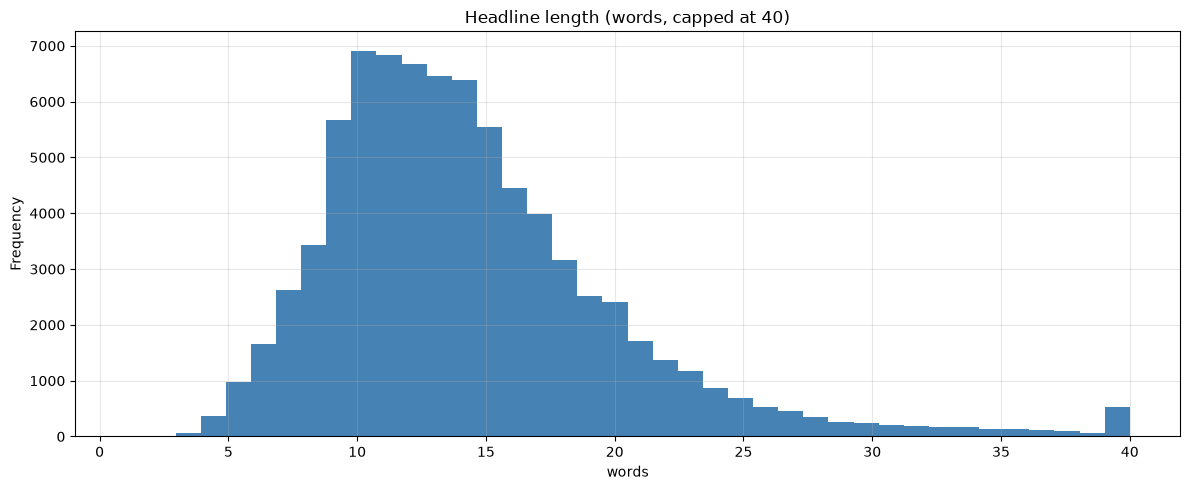

,% missing
title,0.00
summary,41.20
source,18.25
published_at,0.00
finbert_score,0.00


In [7]:
src = articles["source"].fillna("(missing)").value_counts()
display(src.head(10).rename("articles").to_frame().assign(share=lambda d: d["articles"] / len(articles)).style.format({"share": "{:.1%}"}))

title_chars = articles["title"].fillna("").str.len()
title_words = articles["title"].fillna("").str.split().str.len()
display(pd.DataFrame({"characters": title_chars.describe(), "words": title_words.describe()}).round(1))

ax = title_words.clip(upper=40).plot(kind="hist", bins=40, color="steelblue")
ax.set_title("Headline length (words, capped at 40)")
ax.set_xlabel("words")
plt.tight_layout()
plt.show()
plt.close("all")

missing = pd.Series({
    "title": articles["title"].isna().mean(),
    "summary": articles["summary"].isna().mean(),
    "source": articles["source"].isna().mean(),
    "published_at": articles["published_at"].isna().mean(),
    "finbert_score": articles["finbert_score"].isna().mean(),
})
display((missing * 100).round(2).rename("% missing").to_frame())

## 7. Sentiment by company

FinBERT is run once per article and copied to every ticker the article mentions, so these numbers describe the tone of the articles around a company, not the company itself.

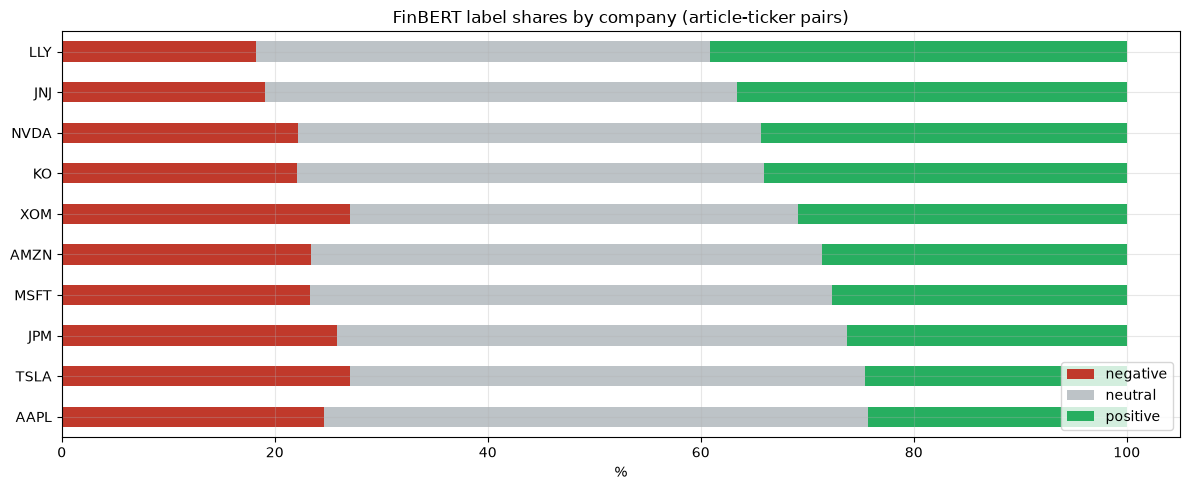

,avg_score_all,avg_score_focused,std_score_all
ticker,,,
AAPL,0.013,0.024,0.575
JPM,0.008,0.038,0.585
MSFT,0.056,0.090,0.585
NVDA,0.112,0.207,0.611
JNJ,0.165,0.241,0.586
XOM,0.035,0.100,0.619
KO,0.097,0.230,0.605
AMZN,0.060,0.096,0.593
LLY,0.194,0.274,0.589


Overall label shares (articles):


,share
finbert_label,
neutral,45.0%
positive,29.9%
negative,25.1%


In [8]:
labels = ["negative", "neutral", "positive"]
share = (
    pairs.groupby(["ticker", "finbert_label"]).size().unstack(fill_value=0)
    .reindex(index=TICKERS, columns=labels, fill_value=0)
)
share_pct = share.div(share.sum(axis=1), axis=0)

ax = (share_pct * 100).sort_values("positive").plot(kind="barh", stacked=True, color=["#c0392b", "#bdc3c7", "#27ae60"])
ax.set_title("FinBERT label shares by company (article-ticker pairs)")
ax.set_xlabel("%")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
plt.close("all")

score = pd.DataFrame({
    "avg_score_all": pairs.groupby("ticker")["finbert_score"].mean(),
    "avg_score_focused": pairs[pairs["is_focused"]].groupby("ticker")["finbert_score"].mean(),
    "std_score_all": pairs.groupby("ticker")["finbert_score"].std(),
}).reindex(TICKERS)
display(score.round(3))
print("Overall label shares (articles):")
display(articles["finbert_label"].value_counts(normalize=True).rename("share").to_frame().style.format("{:.1%}"))

## 8. Save the per-ticker summary and write the findings

In [9]:
summary = (
    per_ticker[["pairs", "distinct_articles", "avg_per_trading_day"]]
    .join(freq[["share_days_without", "mean_on_days_with"]])
    .join(focused_share.rename("share_focused"))
    .join(share_pct.add_prefix("share_"))
    .join(score[["avg_score_all", "avg_score_focused"]])
)
summary.index.name = "ticker"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
summary.round(4).to_csv(SUMMARY_OUT)
print("Saved:", SUMMARY_OUT.resolve())

top, bottom = per_ticker["pairs"].idxmax(), per_ticker["pairs"].idxmin()
sparse = freq["share_days_without"].idxmax()
dense = freq["share_days_without"].idxmin()
roundup_ticker = (1 - focused_share).idxmax()
pos_ticker = score["avg_score_all"].idxmax()
neg_ticker = score["avg_score_all"].idxmin()

print("FINDINGS (copy into the report, edit the wording):")
print(f"1. Coverage is very uneven: {top} has {per_ticker.loc[top, 'pairs']:,} article-ticker pairs and {bottom} only {per_ticker.loc[bottom, 'pairs']:,} "
      f"({per_ticker.loc[top, 'pairs'] / max(per_ticker.loc[bottom, 'pairs'], 1):.0f} times fewer).")
print(f"2. Over time, {int((total_monthly == 0).sum())} of 60 months have no articles at all, and {int((monthly < 5).sum().sum())} of {monthly.size} ticker-months have fewer than 5 articles, "
      f"so monthly sentiment for thinly covered companies must be read with care.")
print(f"3. Share of trading days with no news: {sparse} has no article on {freq.loc[sparse, 'share_days_without']:.0%} of trading days, {dense} on {freq.loc[dense, 'share_days_without']:.0%}. "
      f"A daily sentiment series would be noisy, so we use article-level and monthly views.")
print(f"4. {1 - pairs['is_focused'].mean():.0%} of article-ticker pairs come from roundups with more than {FOCUSED_MAX} tickers; {roundup_ticker} is the most affected "
      f"({1 - focused_share[roundup_ticker]:.0%}). Results are reported with and without them.")
print(f"5. Tone: {articles['finbert_label'].value_counts(normalize=True).get('positive', 0):.0%} of articles are positive, "
      f"{articles['finbert_label'].value_counts(normalize=True).get('negative', 0):.0%} negative. The most positive coverage is {pos_ticker} "
      f"({score.loc[pos_ticker, 'avg_score_all']:+.2f}), the most negative {neg_ticker} ({score.loc[neg_ticker, 'avg_score_all']:+.2f}). "
      f"Missing summary: {missing['summary']:.0%}, missing source: {missing['source']:.0%}.")

Saved: D:\DEPI\MarketPulse Graduation Project\data\processed\news_eda_summary.csv
FINDINGS (copy into the report, edit the wording):
1. Coverage is very uneven: TSLA has 26,896 article-ticker pairs and KO only 1,259 (21 times fewer).
2. Over time, 0 of 60 months have no articles at all, and 0 of 600 ticker-months have fewer than 5 articles, so monthly sentiment for thinly covered companies must be read with care.
3. Share of trading days with no news: KO has no article on 52% of trading days, AAPL on 0%. A daily sentiment series would be noisy, so we use article-level and monthly views.
4. 48% of article-ticker pairs come from roundups with more than 3 tickers; NVDA is the most affected (58%). Results are reported with and without them.
5. Tone: 30% of articles are positive, 25% negative. The most positive coverage is LLY (+0.19), the most negative TSLA (-0.01). Missing summary: 41%, missing source: 18%.


## Completion checklist

- [ ] The notebook runs top to bottom without errors.
- [ ] Section 4 shows the share of trading days without an article for every ticker (this justifies having no daily news table).
- [ ] Section 5 reports the share of roundup articles.
- [ ] The five findings are copied into the report and the numbers are checked against the tables above.
- [ ] `news_eda_summary.csv` is in `data/processed/`.
- [ ] Sentiment is described as article-level, not company-specific.